In [2]:

import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_files = [n for n in z.namelist()
                 if n.endswith("student-mat.csv")]

    if csv_files:
        df = pd.read_csv(z.open(csv_files[0]), sep=";")
    else:
        inner_zip = next(
            n for n in z.namelist()
            if n.endswith(".zip")
        )
        with zipfile.ZipFile(io.BytesIO(z.read(inner_zip))) as inner:
            csv_name = next(
                n for n in inner.namelist()
                if n.endswith("student-mat.csv")
            )
            df = pd.read_csv(inner.open(csv_name), sep=";")

print("VERİ SETİ BAŞARIYLA YÜKLENDİ!")
print("Veri boyutu:", df.shape)
print("Eksik değer sayısı:", df.isnull().sum().sum())

display(df.head())


VERİ SETİ BAŞARIYLA YÜKLENDİ!
Veri boyutu: (395, 33)
Eksik değer sayısı: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


VERİ SETİ ANALİZİ
Veri boyutu: (395, 33)
Eksik değer: 0
Tekrarlanan satır: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Başarı dağılımı:
basari
1    265
0    130
Name: count, dtype: int64


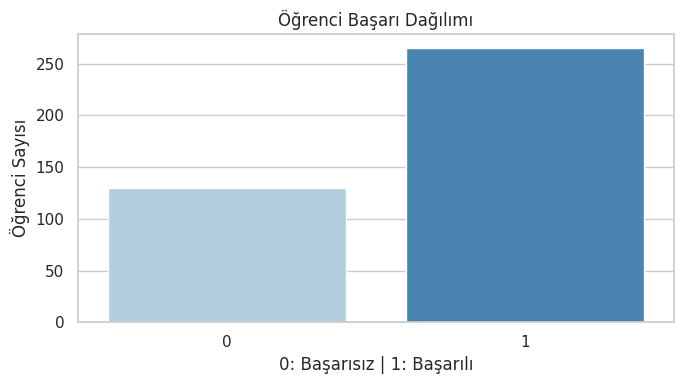

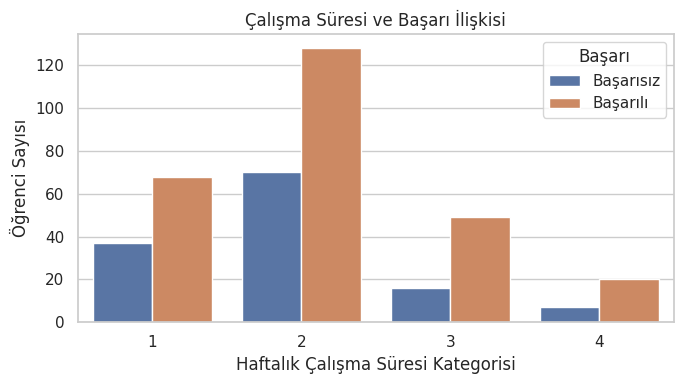

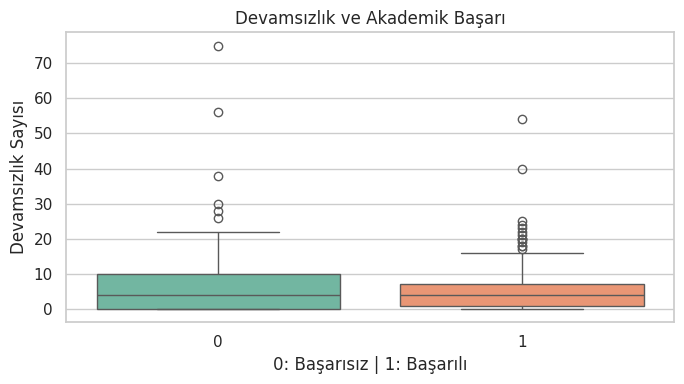


3 grafik başarıyla oluşturuldu!


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Veri seti kontrolü
print("VERİ SETİ ANALİZİ")
print("Veri boyutu:", df.shape)
print("Eksik değer:", df.isnull().sum().sum())
print("Tekrarlanan satır:", df.duplicated().sum())

display(df.describe())

# Hedef değişken: 10 ve üzeri başarılı
df["basari"] = (df["G3"] >= 10).astype(int)

print("\nBaşarı dağılımı:")
print(df["basari"].value_counts())

sns.set_theme(style="whitegrid")

# Grafik 1: Başarı dağılımı
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="basari", hue="basari",
              palette="Blues", legend=False)
plt.title("Öğrenci Başarı Dağılımı")
plt.xlabel("0: Başarısız | 1: Başarılı")
plt.ylabel("Öğrenci Sayısı")
plt.tight_layout()
plt.savefig("grafik1_basari.png", dpi=150)
plt.show()

# Grafik 2: Çalışma süresi ve başarı
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="studytime", hue="basari")
plt.title("Çalışma Süresi ve Başarı İlişkisi")
plt.xlabel("Haftalık Çalışma Süresi Kategorisi")
plt.ylabel("Öğrenci Sayısı")
plt.legend(title="Başarı", labels=["Başarısız", "Başarılı"])
plt.tight_layout()
plt.savefig("grafik2_calisma.png", dpi=150)
plt.show()

# Grafik 3: Devamsızlık ve başarı
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="basari", y="absences",
            hue="basari", palette="Set2",
            legend=False)
plt.title("Devamsızlık ve Akademik Başarı")
plt.xlabel("0: Başarısız | 1: Başarılı")
plt.ylabel("Devamsızlık Sayısı")
plt.tight_layout()
plt.savefig("grafik3_devamsizlik.png", dpi=150)
plt.show()

print("\n3 grafik başarıyla oluşturuldu!")



MODEL: Logistic Regression
              precision    recall  f1-score   support

           0       0.47      0.35      0.40        26
           1       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79



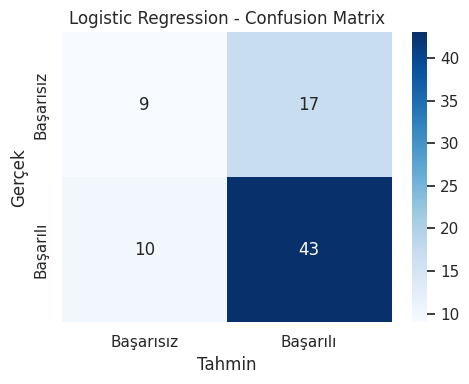


MODEL: Random Forest
              precision    recall  f1-score   support

           0       0.36      0.15      0.22        26
           1       0.68      0.87      0.76        53

    accuracy                           0.63        79
   macro avg       0.52      0.51      0.49        79
weighted avg       0.57      0.63      0.58        79



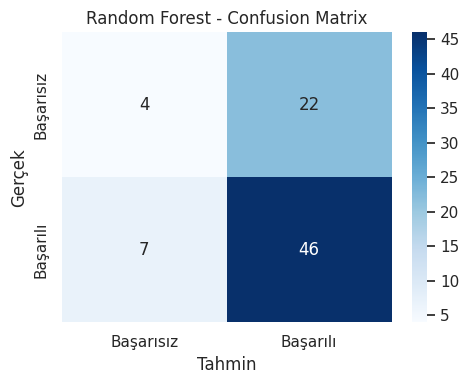

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.6582,0.7167,0.8113,0.7611
1,Random Forest,0.6329,0.6765,0.8679,0.7603



En yüksek test F1 skoruna sahip model: Logistic Regression
Model eğitimi tamamlandı!


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# 1. Hedef ve özellikler
y = (df["G3"] >= 10).astype(int)

# G1 ve G2 önceki notlardır.
# G3 hedef nottur. Veri sızıntısını önlemek için çıkarıyoruz.
X = df.drop(
    columns=["G1", "G2", "G3", "basari"],
    errors="ignore"
)

# 2. Eğitim ve test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Değişken türleri
numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 4. Ön işleme
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# 5. Modeller
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    )
}

results = []
trained_models = {}

# 6. Eğitim ve değerlendirme
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    print("\nMODEL:", name)
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Başarısız", "Başarılı"],
        yticklabels=["Başarısız", "Başarılı"]
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Tahmin")
    plt.ylabel("Gerçek")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(
        f"confusion_{filename}.png", dpi=150
    )
    plt.show()

# 7. Model karşılaştırması
results_df = pd.DataFrame(results)
display(results_df.round(4))

results_df.to_csv(
    "model_sonuclari.csv", index=False
)

best_model_name = results_df.loc[
    results_df["F1"].idxmax(), "Model"
]

print("\nEn yüksek test F1 skoruna sahip model:",
      best_model_name)
print("Model eğitimi tamamlandı!")


MODEL KARŞILAŞTIRMA SONUÇLARI


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.6582,0.7167,0.8113,0.7611
1,Random Forest,0.6329,0.6765,0.8679,0.7603


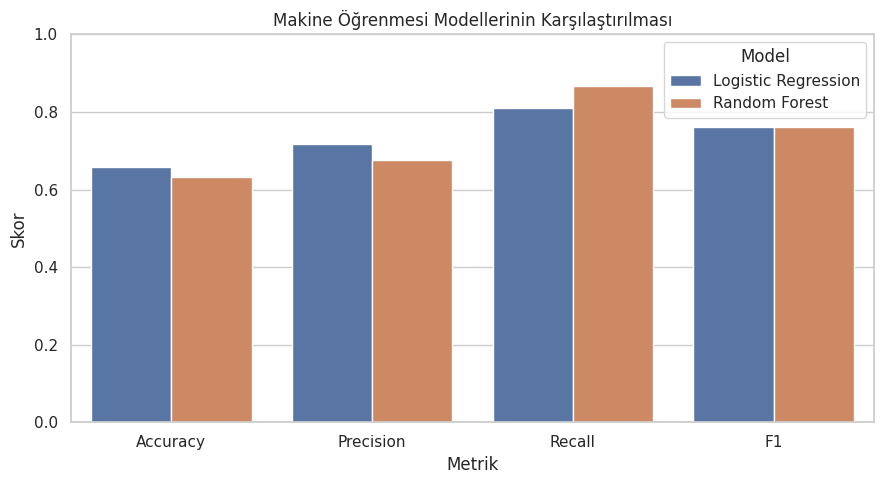


MODEL: Logistic Regression
Doğru başarısız tahmini: 9
Yanlış başarılı tahmini: 17
Yanlış başarısız tahmini: 10
Doğru başarılı tahmini: 43
Toplam yanlış tahmin: 27

MODEL: Random Forest
Doğru başarısız tahmini: 4
Yanlış başarılı tahmini: 22
Yanlış başarısız tahmini: 7
Doğru başarılı tahmini: 46
Toplam yanlış tahmin: 29

EN İYİ MODEL: Logistic Regression
Yanlış tahmin edilen öğrenci sayısı: 27


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,Gercek,Tahmin
305,GP,F,18,U,GT3,T,2,4,services,at_home,...,no,4,4,3,1,1,3,8,1,0
67,GP,F,16,U,GT3,T,3,1,services,other,...,no,4,3,3,1,2,5,4,0,1
86,GP,F,16,U,LE3,T,2,2,at_home,other,...,no,4,3,4,1,2,2,4,0,1
136,GP,M,17,R,GT3,T,3,4,at_home,other,...,no,5,4,5,2,4,5,0,0,1
89,GP,M,16,U,LE3,A,4,4,teacher,health,...,no,4,1,3,3,5,5,18,0,1
340,GP,F,19,U,GT3,T,2,1,services,services,...,yes,4,3,4,1,3,3,4,1,0
333,GP,F,18,U,LE3,T,2,2,other,other,...,yes,4,3,3,1,1,2,0,0,1
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,no,4,1,4,1,1,1,6,0,1
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,no,3,2,3,3,3,5,5,0,1
332,GP,F,18,U,GT3,T,3,3,services,services,...,no,5,3,4,1,1,4,0,0,1



Hata analizi tamamlandı!


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Modellerin karşılaştırılması
print("MODEL KARŞILAŞTIRMA SONUÇLARI")
display(results_df.round(4))

# 2. Başarı metriklerinin görselleştirilmesi
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metrik",
    value_name="Skor"
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=plot_df,
    x="Metrik",
    y="Skor",
    hue="Model"
)
plt.ylim(0, 1)
plt.title("Makine Öğrenmesi Modellerinin Karşılaştırılması")
plt.tight_layout()
plt.savefig("model_karsilastirma.png", dpi=150)
plt.show()

# 3. Her model için hata analizi
for name, model in trained_models.items():
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    print("\nMODEL:", name)
    print("Doğru başarısız tahmini:", tn)
    print("Yanlış başarılı tahmini:", fp)
    print("Yanlış başarısız tahmini:", fn)
    print("Doğru başarılı tahmini:", tp)
    print("Toplam yanlış tahmin:", fp + fn)

# 4. En yüksek F1 skoruna sahip model
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

error_analysis = X_test.copy()
error_analysis["Gercek"] = y_test
error_analysis["Tahmin"] = best_predictions

errors = error_analysis[
    error_analysis["Gercek"] !=
    error_analysis["Tahmin"]
]

print("\nEN İYİ MODEL:", best_model_name)
print("Yanlış tahmin edilen öğrenci sayısı:", len(errors))

display(errors.head(10))

# 5. Rapor için dosyaları kaydet
errors.to_csv(
    "hata_analizi.csv",
    index=False
)

print("\nHata analizi tamamlandı!")


In [6]:

print("=== VERİ SETİ ===")
print("Öğrenci sayısı:", len(df))
print("Değişken sayısı:", X.shape[1])
print("Başarılı öğrenci:", (y == 1).sum())
print("Başarısız öğrenci:", (y == 0).sum())

print("\n=== MODEL SONUÇLARI ===")
print(results_df.to_string(index=False))

print("\n=== EN YÜKSEK F1 SKORLU MODEL ===")
print(best_model_name)

print("\n=== HATA ANALİZİ ===")
print("Yanlış tahmin sayısı:", len(errors))
print("Test verisi sayısı:", len(X_test))


=== VERİ SETİ ===
Öğrenci sayısı: 395
Değişken sayısı: 30
Başarılı öğrenci: 265
Başarısız öğrenci: 130

=== MODEL SONUÇLARI ===
              Model  Accuracy  Precision   Recall       F1
Logistic Regression  0.658228   0.716667 0.811321 0.761062
      Random Forest  0.632911   0.676471 0.867925 0.760331

=== EN YÜKSEK F1 SKORLU MODEL ===
Logistic Regression

=== HATA ANALİZİ ===
Yanlış tahmin sayısı: 27
Test verisi sayısı: 79
